In [1]:
import pandas as pd
from pathlib import Path

data_path = Path("..") / "Day48" / "cleaned_customer_data.csv"

df = pd.read_csv(data_path)

print("Customer Intelligence Platform")
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

df.head()

Customer Intelligence Platform
Dataset loaded successfully!
Dataset shape: (51290, 28)
Missing values: 0


,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,shipping_cost,order_priority,year,shipping_days,profit_margin,order_month,order_day,order_day_of_week,sales_category,profit_status
0,AG-2011-2040,2011-01-01,2011-01-06,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,35.46,Medium,2011,5,26.014706,1,1,5,Medium,Profit
1,IN-2011-47883,2011-01-01,2011-01-08,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,9.72,Medium,2011,7,30.030000,1,1,5,Medium,Profit
2,HU-2011-1220,2011-01-01,2011-01-05,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,8.17,High,2011,4,44.909091,1,1,5,Low,Profit
3,IT-2011-3647632,2011-01-01,2011-01-05,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,4.82,High,2011,4,-57.900000,1,1,5,Low,Loss
4,IN-2011-47883,2011-01-01,2011-01-08,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,4.70,Medium,2011,7,33.131579,1,1,5,Medium,Profit


In [2]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nTotal Sales:", round(df["sales"].sum(), 2))
print("Total Profit:", round(df["profit"].sum(), 2))
print("Unique Customers:", df["customer_name"].nunique())

print("\nSales by Customer Segment:")
print(df.groupby("segment")["sales"].sum().round(2))

print("\nProfit by Customer Segment:")
print(df.groupby("segment")["profit"].sum().round(2))

Dataset shape: (51290, 28)
Missing values: 0
Duplicate rows: 0

Total Sales: 12642905.0
Total Profit: 1469034.82
Unique Customers: 795

Sales by Customer Segment:
segment
Consumer       6508141.0
Corporate      3824808.0
Home Office    2309956.0
Name: sales, dtype: float64

Profit by Customer Segment:
segment
Consumer       749239.78
Corporate      442785.86
Home Office    277009.18
Name: profit, dtype: float64


Monthly Sales Analysis
order_month
1      675141.0
2      543768.0
3      770519.0
4      698603.0
5      904061.0
6     1269751.0
7      749423.0
8     1293852.0
9     1437432.0
10    1168220.0
11    1551319.0
12    1580816.0
Name: sales, dtype: float64


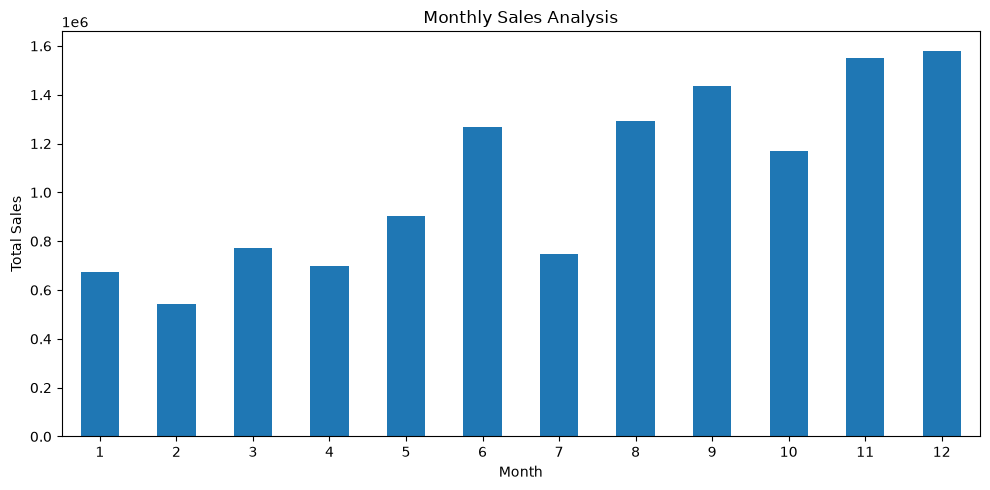

In [3]:
monthly_sales = df.groupby("order_month")["sales"].sum()

print("Monthly Sales Analysis")
print(monthly_sales)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
monthly_sales.plot(kind="bar")
plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Monthly Profit Analysis
order_month
1      73535.38454
2      72509.72922
3      94087.52096
4      73513.63124
5     104509.78428
6     147079.41684
7      78070.09172
8     151854.10972
9     170438.18316
10    157269.35838
11    175449.48412
12    170718.12710
Name: profit, dtype: float64


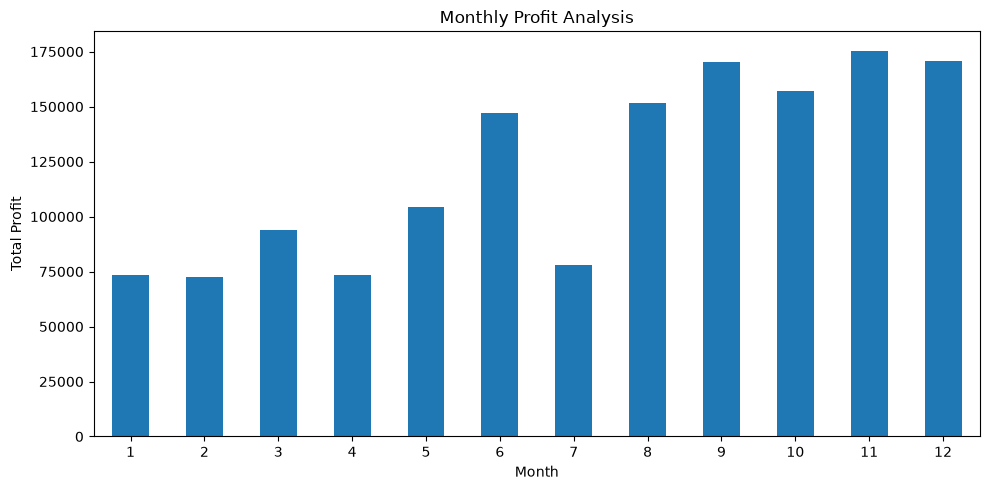

In [4]:
monthly_profit = df.groupby("order_month")["profit"].sum()

print("Monthly Profit Analysis")
print(monthly_profit)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
monthly_profit.plot(kind="bar")
plt.title("Monthly Profit Analysis")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Profit by Product Category
category
Technology         663778.73318
Office Supplies    518473.83430
Furniture          286782.25380
Name: profit, dtype: float64


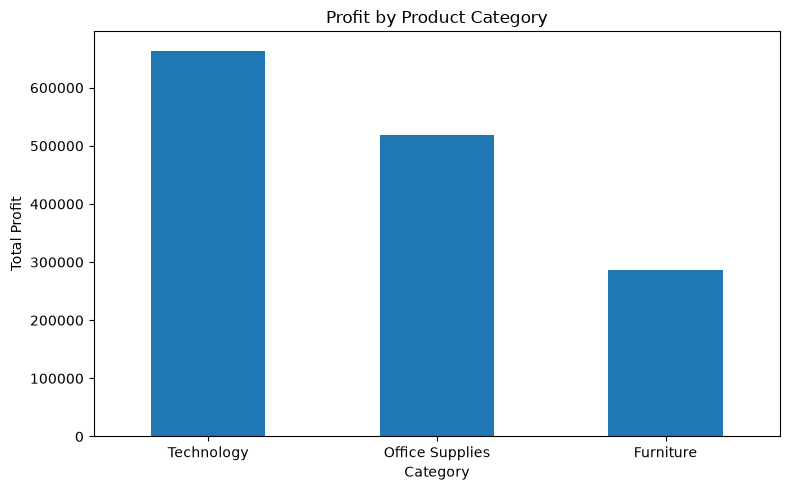

In [5]:
category_profit = df.groupby("category")["profit"].sum().sort_values(ascending=False)

print("Profit by Product Category")
print(category_profit)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
category_profit.plot(kind="bar")
plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Sales and Profit by Customer Segment
                 sales        profit
segment                             
Consumer     6508141.0  749239.78206
Corporate    3824808.0  442785.85866
Home Office  2309956.0  277009.18056


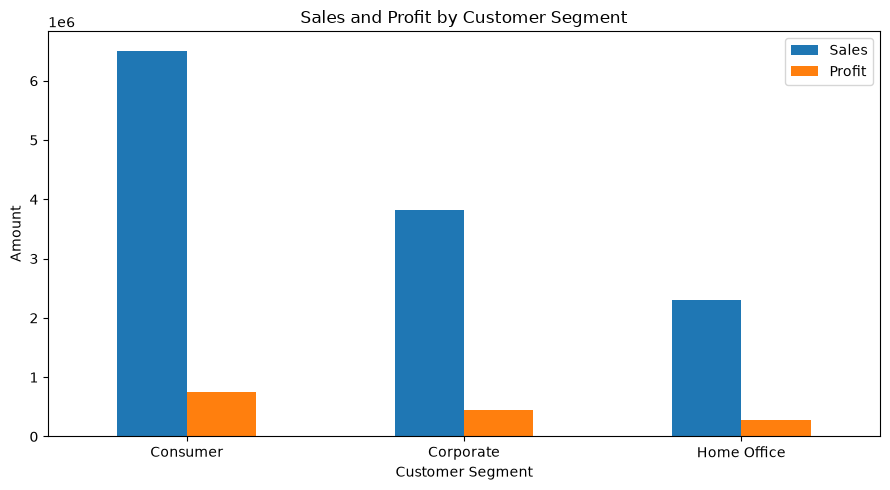

In [6]:
segment_analysis = df.groupby("segment")[["sales", "profit"]].sum()

print("Sales and Profit by Customer Segment")
print(segment_analysis)

segment_analysis.plot(kind="bar", figsize=(9, 5))
plt.title("Sales and Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.legend(["Sales", "Profit"])
plt.tight_layout()
plt.show()

In [7]:
monthly_sales = df.groupby("order_month")["sales"].sum()
monthly_profit = df.groupby("order_month")["profit"].sum()
category_profit = df.groupby("category")["profit"].sum()
segment_analysis = df.groupby("segment")[["sales", "profit"]].sum()

monthly_sales.to_csv("../Day49/monthly_sales.csv")
monthly_profit.to_csv("../Day49/monthly_profit.csv")
category_profit.to_csv("../Day49/category_profit.csv")
segment_analysis.to_csv("../Day49/segment_analysis.csv")

print("All analysis results saved successfully!")

All analysis results saved successfully!
